# 04 Testing DLS

*This notebook covers **Step 6 (Experiments)**: the actual DLS fairness test.*

## The question

If rain ends a chase early, DLS compares the chasing team's score with a **par score** worked out from the overs and wickets they had left. Ahead of par they win, behind it they lose. For that to be fair, a team sitting exactly on par should have about a 50% chance of winning had the match carried on.

## The method

The ~4,500 uninterrupted 20-over chases already have a known result. So for every ball, work out the DLS par score *as if* rain had ended the match right then, find the moments where the chasing team was on par, and check how often they actually went on to win.

This uses **real outcomes, not the model**. That avoids the model's calibration error from notebook 03, and avoids relying on it in unusual situations. (Testing showed the model gives nonsense for states that never happen in real matches, like 125/8 after 5 overs.)

## DLS version

The ICC uses the DLS Professional (Stern) Edition, which is proprietary software. This uses the publicly available **Standard Edition** resource table from the ICC's DLS methodology document, saved in `reference/dls_standard_edition.csv`. Results describe the Standard Edition, which may differ from the version used in international matches.

## Loading the resource table

The table gives the % of a team's batting resources remaining for each number of overs left (50 down to 0) and wickets lost (0 to 9). It's over-by-over, so values between whole overs are linearly interpolated. With 10 wickets lost, resources are 0.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

table = pd.read_csv("reference/dls_standard_edition.csv").sort_values("overs_left")

def resources_left(balls_left, wickets):
    """% of resources remaining, interpolated between whole overs."""
    overs_left = np.asarray(balls_left) / 6
    wickets = np.asarray(wickets)
    out = np.zeros(len(overs_left))          # 10 wickets down = 0
    for w in range(10):
        m = wickets == w
        out[m] = np.interp(overs_left[m], table["overs_left"], table[f"w{w}"])
    return out

R1 = resources_left([120], [0])[0]
print("T20 starting resources:", R1)

T20 starting resources: 56.6


## Par score at every ball

For a T20 the first team starts with the resources for 20 overs and 0 wickets lost (R1). If the chase ends with the second team having used resources R2 (which is less than R1), the Standard Edition par score is:

**par = S × R2 / R1**, where S is the first-innings total.

Only full 20-over chases are used, and only points after at least 5 overs, since a T20 needs 5 overs in the chase for a result.

In [2]:
df = pd.read_csv("data/chases.csv")
normal = df[~df["dls"]].copy()

# keep full 20-over chases only
full = normal.groupby("match_id")["balls_left"].transform("max") >= 119
normal = normal[full]

normal["r_left"] = resources_left(normal["balls_left"], normal["wickets"])
normal["par"] = (normal["target"] - 1) * (R1 - normal["r_left"]) / R1
normal["margin"] = normal["runs"] - normal["par"]

# at least 5 overs bowled, innings still alive
s = normal[(normal["balls_left"] <= 90) & (normal["balls_left"] > 0) & (normal["wickets"] < 10)]

print(normal["match_id"].nunique(), "full chases")
s[["runs", "wickets", "balls_left", "par", "margin", "won"]].head(10)

4493 full chases


,runs,wickets,balls_left,par,margin,won
32,92,0,90,51.964664,40.035336,1
33,98,0,89,53.863958,44.136042,1
34,98,0,88,55.763251,42.236749,1
35,100,0,87,57.662544,42.337456,1
36,102,0,86,59.561837,42.438163,1
37,102,0,85,61.461131,40.538869,1
38,102,0,84,63.360424,38.639576,1
39,103,0,83,65.259717,37.740283,1
40,109,0,82,67.159011,41.840989,1
41,109,0,81,69.058304,39.941696,1


## Sanity check: does being ahead of par help?

Before testing fairness at exactly par, check DLS points the right way: teams further ahead of par should win more often.

In [3]:
bands = pd.cut(s["margin"], [-30, -15, -8, -3, 3, 8, 15, 30])
check = s.assign(band=bands).drop_duplicates(["match_id", "band"])
check.groupby("band", observed=True)["won"].agg(matches="count", win_rate="mean").round(3)

,matches,win_rate
band,,
"(-30, -15]",1985,0.113
"(-15, -8]",2108,0.237
"(-8, -3]",2163,0.358
"(-3, 3]",2270,0.512
"(3, 8]",2168,0.657
"(8, 15]",2118,0.779
"(15, 30]",1824,0.900


## Win rate at par, by wickets lost

"On par" means within 2 runs of the par score. A match can pass through par many times, so each match counts **once per number of wickets lost** (its first moment on par with that many down). That stops one match dominating a group, but it doesn't make the groups fully independent: the same match can appear at several wicket counts (say on par at 3 down and again at 5 down), and when wicket counts are combined into bands later, a match can appear more than once in the same band. Rows from one match share one result, so the error bars below are slightly too narrow. Notebook 06 checks the main result with a match-level bootstrap that allows for this.

The 95% interval is ± 1.96 × √(p(1−p)/n). If 50% sits outside it, the difference is unlikely to be chance.

In [4]:
on_par = s[s["margin"].abs() <= 2]
first = (on_par.sort_values("balls_left", ascending=False)
               .drop_duplicates(["match_id", "wickets"]))

res = first.groupby("wickets")["won"].agg(n="count", win_rate="mean")
res["ci"] = 1.96 * np.sqrt(res["win_rate"] * (1 - res["win_rate"]) / res["n"])
res["low"], res["high"] = res["win_rate"] - res["ci"], res["win_rate"] + res["ci"]

print("overall win rate at par:", round(first["won"].mean(), 3), "from", first["match_id"].nunique(), "matches")
res.round(3)

overall win rate at par: 0.522 from 2114 matches


,n,win_rate,ci,low,high
wickets,,,,,
0,171,0.456,0.075,0.381,0.531
1,653,0.495,0.038,0.456,0.533
2,983,0.517,0.031,0.486,0.548
3,816,0.553,0.034,0.519,0.587
4,690,0.577,0.037,0.540,0.614
5,509,0.546,0.043,0.503,0.589
6,364,0.525,0.051,0.473,0.576
7,211,0.450,0.067,0.383,0.517
8,146,0.397,0.079,0.318,0.477


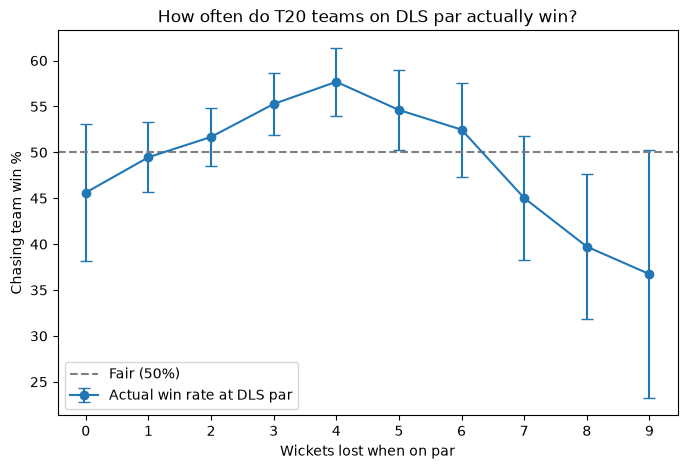

In [5]:
import os
os.makedirs("figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(res.index, res["win_rate"] * 100, yerr=res["ci"] * 100,
            fmt="o-", capsize=4, label="Actual win rate at DLS par")
ax.axhline(50, ls="--", color="grey", label="Fair (50%)")
ax.set_xticks(range(10))
ax.set_xlabel("Wickets lost when on par")
ax.set_ylabel("Chasing team win %")
ax.set_title("How often do T20 teams on DLS par actually win?")
ax.legend()
plt.savefig("figures/win_at_par_by_wickets.png", dpi=150, bbox_inches="tight")
plt.show()

## Is it wickets, or timing?

Teams on par with 0-1 wickets down are almost always early in the chase, and teams 8-9 down are almost always late. So the pattern above could partly be about *when* in the innings a team is on par, not how many wickets they've lost. Splitting by phase compares like with like.

In [6]:
first["phase"] = pd.cut(first["balls_left"], [0, 30, 60, 90],
                        labels=["last 5 overs", "overs 11-15", "overs 6-10"])
first["wkt_group"] = pd.cut(first["wickets"], [-1, 2, 5, 9],
                            labels=["0-2 down", "3-5 down", "6-9 down"])
(first.groupby(["phase", "wkt_group"], observed=True)["won"]
      .agg(n="count", win_rate="mean").round(3)
      .unstack("wkt_group"))

n                   win_rate                  
wkt_group    0-2 down 3-5 down 6-9 down 0-2 down 3-5 down 6-9 down
phase                                                             
last 5 overs       29      732      712    0.586    0.604    0.468
overs 11-15       285      828       57    0.607    0.533    0.491
overs 6-10       1493      455        1    0.482    0.536    1.000

## Results

**1. DLS points the right way.** Win rate climbs steadily with the margin over par, from 11% for teams 15-30 runs behind to 90% for teams 15-30 ahead, with teams within 3 runs of par winning 51%.

**2. On average, DLS par is fair.** Across 2,114 matches, teams on par won 52.2%. That's in line with the normal advantage of chasing (about 52% across all matches), so on average the Standard Edition par score gives neither side an edge.

**3. But it isn't fair for every number of wickets.** Win rate at par forms an inverted U: teams 3-5 down win 55-58% (all with error bars above 50%, though 5 down only just), while teams 8 down win only 40% (clearly below). The rest have error bars that cross 50%, mostly because those situations are rare (only 49 matches at 9 down, for example).

**4. Controlling for timing makes the pattern clearer.** The low win rate at 0-1 wickets down turned out to be mostly a timing effect: those teams are nearly all in overs 6-10, where DLS is roughly fair (48-54%). Comparing teams at the same stage of the chase:

| Phase | 0-2 down | 3-5 down | 6-9 down |
|---|---|---|---|
| Overs 6-10 | 48% | 54% | (1 match) |
| Overs 11-15 | **61%** | 53% | 49% (57 matches) |
| Last 5 overs | (29 matches) | **60%** | 47% |

From over 11 onwards, **the more wickets a team has in hand at par, the more likely it is to win**. In the last 5 overs, teams 3-5 down win 60% and teams 6-9 down win 47%, a gap of 14 points. Allowing for matches that appear in both groups (notebook 06), the 95% interval for that gap is about 8 to 19 points, so it is very unlikely to be chance. In overs 11-15, teams 0-2 down win 61% against 53% for teams 3-5 down.

**Conclusion: the DLS Standard Edition undervalues wickets in hand in T20, especially in the second half of a chase.** A team with plenty of wickets left gets a par score that is too high (DLS is harsh on them), while a team with few left gets one that is too low (DLS is generous to them). A likely reason: DLS was built for 50-over cricket, where wickets are preserved for a long innings. In T20 there are too few balls left to use them all, so a team with wickets in hand late in a chase can attack freely, which is worth more than the 50-over table assumes.

### Limitations

- **Standard, not Professional Edition.** International matches use the proprietary DLS Professional (Stern) Edition, which was updated partly to handle high-scoring and shorter games. These results describe the public Standard Edition and may overstate the bias in the version actually used.
- **This tests termination only.** It asks what happens if rain *ends* a chase. DLS is also used to set revised targets before or during a chase, which isn't tested here.
- **Small samples at the extremes.** Situations like being on par with 9 wickets down are rare, so those estimates are uncertain. Only differences whose error bars clear 50% are treated as real.
- **Choices that affect the numbers.** "On par" means within 2 runs, and only full 20-over chases after 5 overs are used. Notebook 06 reruns the main result with other choices.
- **Not fully independent.** A match can appear at more than one wicket count, so the groups aren't fully independent and the simple error bars here are slightly too narrow. Notebook 06 uses a match-level bootstrap for the main gap, which widens its interval a little without changing the conclusion.
- **T20Is and IPL are combined.** Chasing teams win more often in the IPL, so the two competitions might behave differently.